In [3]:
### Code to import tiff images and check their properties
import os
import numpy as np
import tifffile as tiff
from tqdm import tqdm
# ================= CONFIGURATION =================

INPUT_FOLDER = r"/home/students/rawat/czi_output/Processed_images_float32_GreenAndRed/PN_KC_488_568_Brain5_CalyxL_LSMPlus_16bit.ome.tif"

img = tiff.imread(INPUT_FOLDER)
print(f"Image shape: {img.shape}, dtype: {img.dtype}")

## code to display a slice of the image
import matplotlib.pyplot as plt
slice_index = img.shape[1] // 2  # Middle slice
plt.imshow(img[slice_index], cmap='gray')
plt.title(f"Slice {slice_index}")
plt.show()

Image shape: (2, 38, 1101, 1101), dtype: float32


IndexError: index 19 is out of bounds for axis 0 with size 2

ORIGINAL  : uint8 | Range: 0 to 255
Shape (C, Z, Y, X): (3, 92, 1431, 1431)
Detected format (C, Z, H, W). Keeping original orientation.
Image shape (final): (3, 92, 1431, 1431)

Selected for comparison: Channel 0, Z-slice 46
Selected image shape (Y, X): (1431, 1431)
Percentile values: low=0.0, high=196.47464000014588


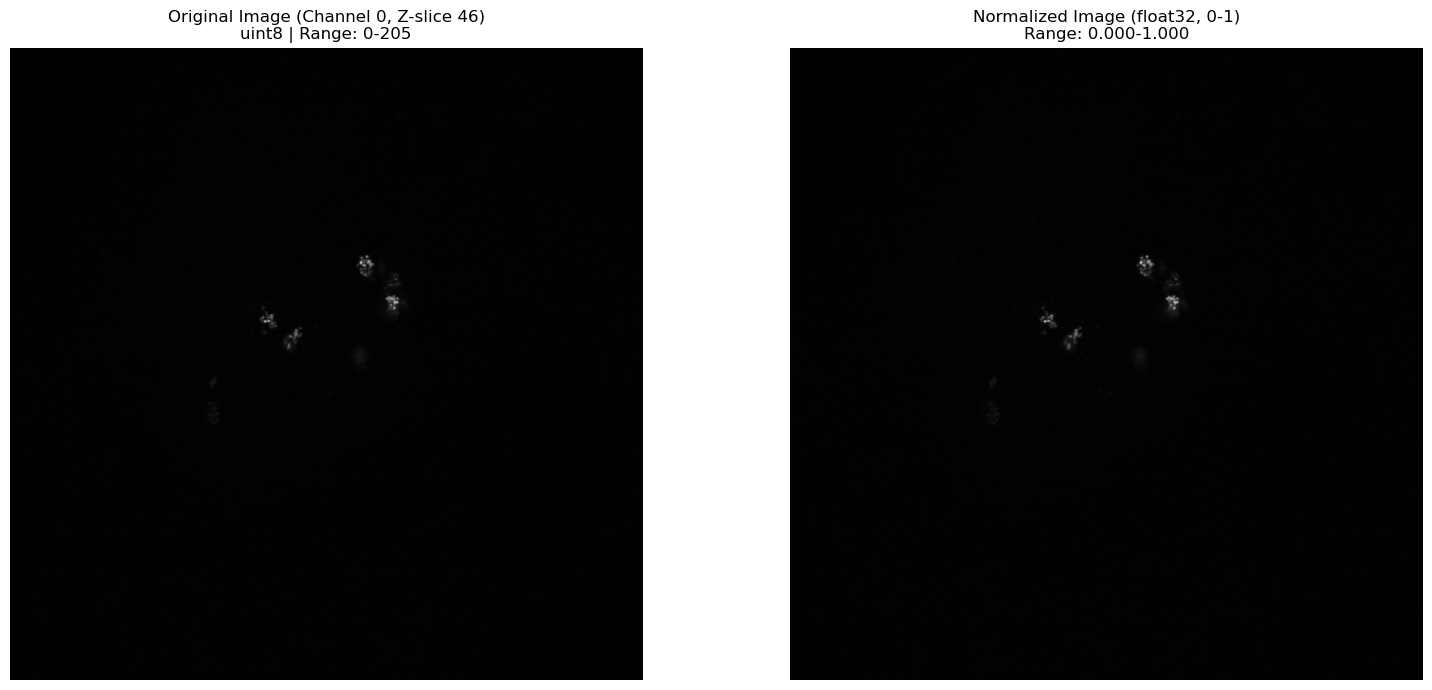

In [ ]:
INPUT_PATH = r"D:\Thesis_images\All_images_tif\old_images\PN_KC_Calyx_CS-_GFP_mCherry568_anti-synapsin633_brain1.ome.tif"
img = tifffile.imread(INPUT_PATH)
print(f"ORIGINAL  : {img.dtype} | Range: {img.min()} to {img.max()}")
print(f"Shape (C, Z, Y, X): {img.shape}")

def fix_dimensions(image):
    if image.ndim == 4 and image.shape[0] > image.shape[1]:
        print("Detected format (Z, C, H, W). Transposing to (C, Z, H, W)...")
        # Swap axis 0 and 1 to move Channel to the front
        image = np.transpose(image, (1, 0, 2, 3))
    else:
        print("Detected format (C, Z, H, W). Keeping original orientation.")

    # if the number of channels are 2 add a black channel as the third channel
    if image.ndim == 4 and image.shape[0] == 2:
        print("Detected 2 channels. Adding a black channel as the third channel...")
        black_channel = np.zeros((1, *image.shape[1:]), dtype=image.dtype)
        image = np.concatenate((image, black_channel), axis=0)
    print(f"Image shape (final): {image.shape}")
    return image

# --- 1. FIX DIMENSIONS IF NEEDED ---
img = fix_dimensions(img)

# --- 2. SELECT SPECIFIC IMAGE FOR COMPARISON ---
# Select Channel 0, Z-slice 30 (middle slice)
CHANNEL = 0
Z_SLICE = img.shape[1] // 2  # Middle z-slice
img_selected = img[CHANNEL, Z_SLICE, :, :]  # Now 2D (Y, X)
print(f"\nSelected for comparison: Channel {CHANNEL}, Z-slice {Z_SLICE}")
print(f"Selected image shape (Y, X): {img_selected.shape}")

# --- 3. NORMALIZE SELECTED IMAGE ---
low, high = np.percentile(img_selected, (0.00001, 99.9999))
print(f"Percentile values: low={low}, high={high}")

if high > low:
    # Normalize to 0-1 as float32
    img_float = (img_selected.astype(np.float32) - low) / (high - low)
    img_float = np.clip(img_float, 0, 1)
else:
    # Flat image fallback
    img_float = np.zeros_like(img_selected, dtype=np.float32)

# --- 4. PLOT COMPARISON ---
fig, ax = plt.subplots(1, 2, figsize=(16, 7))

# Left: Original Image
ax[0].imshow(img_selected, cmap='gray')
ax[0].set_title(f"Original Image (Channel {CHANNEL}, Z-slice {Z_SLICE})\n{img_selected.dtype} | Range: {img_selected.min()}-{img_selected.max()}", fontsize=12)
ax[0].axis('off')

# Right: Normalized Image
ax[1].imshow(img_float, cmap='gray')
ax[1].set_title(f"Normalized Image (float32, 0-1)\nRange: {img_float.min():.3f}-{img_float.max():.3f}", fontsize=12)
ax[1].axis('off')

plt.tight_layout()
plt.show()


In [11]:
print("\n--- FULL DATASET STATISTICS ---")
print(f"Full Shape (C, Z, Y, X): {img.shape}")
print(f"Data Type (dtype): {img.dtype}")
print(f"Minimum Value: {img.min()}")
print(f"Maximum Value: {img.max()}")
print(f"Mean Value:    {img.mean():.2f}")

print("\n--- SELECTED IMAGE STATISTICS ---")
print(f"Selected image shape (Y, X): {img_selected.shape}")
print(f"Minimum Value: {img_selected.min()}")
print(f"Maximum Value: {img_selected.max()}")
print(f"Mean Value:    {img_selected.mean():.2f}")

print("\n--- NORMALIZED IMAGE STATISTICS ---")
print(f"Data Type: {img_float.dtype}")
print(f"Minimum Value: {img_float.min():.6f}")
print(f"Maximum Value: {img_float.max():.6f}")
print(f"Mean Value:    {img_float.mean():.6f}")


Processed shape (Z, Y, X): (75, 1101, 1101, 2)
The data type is uint16, normalizing to uint8.

--- FULL DATASET STATISTICS ---
Full Shape (C, Z, Y, X): (3, 92, 1431, 1431)
Data Type (dtype): uint8
Minimum Value: 0
Maximum Value: 255
Mean Value:    4.14

--- SELECTED IMAGE STATISTICS ---
Selected image shape (Y, X): (1431, 1431)
Minimum Value: 0
Maximum Value: 205
Mean Value:    2.17

--- NORMALIZED IMAGE STATISTICS ---
Data Type: float32
Minimum Value: 0.000000
Maximum Value: 1.000000
Mean Value:    0.011049


In [4]:
LABEL_PATH = r"/home/students/rawat/training_data/data/train/labels/Brain2_PN_KC_Group3_25minfix_OvernightSecAB_488_561_Calyx1_Confocal_slice_0015.tif"

label = tifffile.imread(LABEL_PATH)

print(label.shape)

(1101, 1101)


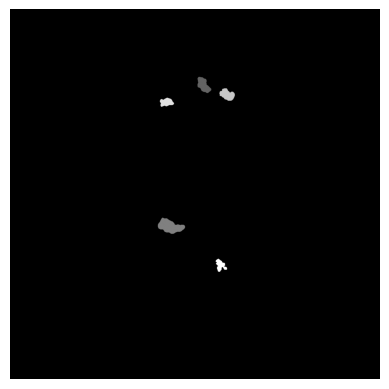

In [5]:
plt.imshow(label, cmap='gray')
plt.axis('off')
plt.show()

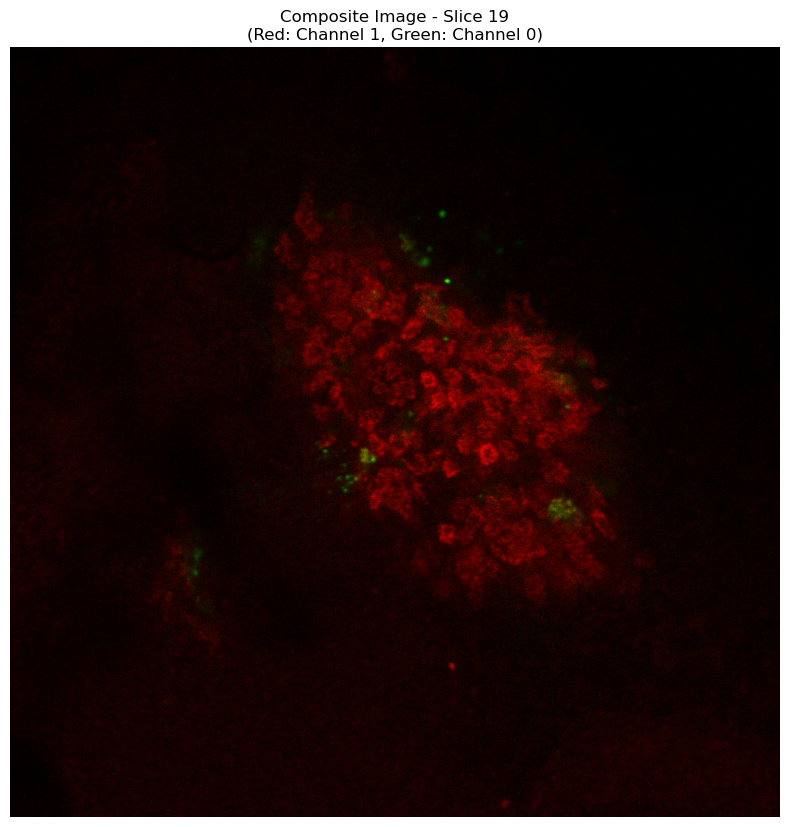

Displayed composite middle slice 19 of 38 total slices


In [6]:
# Display both channels overlaid in the same image (green and red)
middle_slice = img.shape[1] // 2  # Middle z-slice (index 19 for 38 slices)

# Get the two channels
ch0 = img[0, middle_slice, :, :]  # Green channel
ch1 = img[1, middle_slice, :, :]  # Red channel

# Create RGB image: Red channel in R, Green channel in G, Blue channel as zeros
rgb_image = np.zeros((ch0.shape[0], ch0.shape[1], 3), dtype=np.float32)
rgb_image[:, :, 0] = ch1  # Red from channel 1
rgb_image[:, :, 1] = ch0  # Green from channel 0
rgb_image[:, :, 2] = 0         # Blue channel empty

# Display the composite image
plt.figure(figsize=(10, 10))
plt.imshow(rgb_image)
plt.title(f'Composite Image - Slice {middle_slice}\n(Red: Channel 1, Green: Channel 0)')
plt.axis('off')
plt.show()

print(f"Displayed composite middle slice {middle_slice} of {img.shape[1]} total slices")